Clustering Steps:
Step 1: Merge 3 and 4, Distance = 1.00
Step 2: Merge 0 and 1, Distance = 1.41
Step 3: Merge 2 and 7, Distance = 1.41
Step 4: Merge 5 and 6, Distance = 1.41
Step 5: Merge 8 and 9, Distance = 6.40


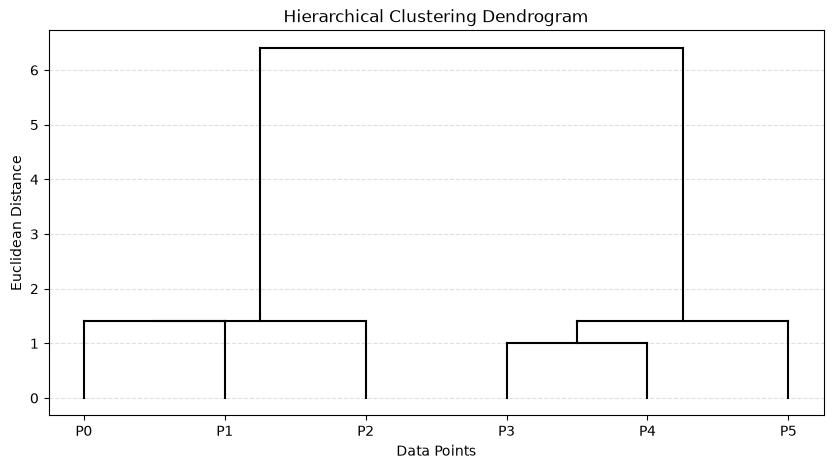

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Dataset
X = np.array([
    [1, 2],
    [2, 3],
    [3, 4],
    [8, 8],
    [9, 8],
    [10, 9]
])


def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))



def hierarchical_clustering(X):

    n = len(X)

    clusters = {i: [i] for i in range(n)}
    next_id = n

    history = []

    while len(clusters) > 1:

        min_dist = float('inf')
        best_pair = None

        keys = list(clusters.keys())

       
        for i in range(len(keys)):
            for j in range(i + 1, len(keys)):

                c1 = clusters[keys[i]]
                c2 = clusters[keys[j]]

               
                d = min(
                    euclidean(X[p1], X[p2])
                    for p1 in c1
                    for p2 in c2
                )

                if d < min_dist:
                    min_dist = d
                    best_pair = (keys[i], keys[j])

        id1, id2 = best_pair

        c1 = clusters[id1]
        c2 = clusters[id2]

        
        history.append((id1, id2, min_dist, len(c1) + len(c2)))

       
        clusters[next_id] = c1 + c2

        del clusters[id1]
        del clusters[id2]

        next_id += 1

    return history


# Perform clustering
history = hierarchical_clustering(X)

print("Clustering Steps:")

for i, (c1, c2, dist, size) in enumerate(history, 1):
    print(f"Step {i}: Merge {c1} and {c2}, "
          f"Distance = {dist:.2f}")


# Draw dendrogram manually
def plot_dendrogram(history, n):

    positions = {i: i for i in range(n)}
    heights = {i: 0 for i in range(n)}

    plt.figure(figsize=(10, 5))

    for step, (id1, id2, dist, size) in enumerate(history):

        x1 = positions[id1]
        x2 = positions[id2]

        y1 = heights[id1]
        y2 = heights[id2]

        # Draw vertical and horizontal lines
        plt.plot([x1, x1], [y1, dist], 'k-')
        plt.plot([x2, x2], [y2, dist], 'k-')
        plt.plot([x1, x2], [dist, dist], 'k-')

        # New cluster position
        new_id = n + step

        positions[new_id] = (x1 + x2) / 2
        heights[new_id] = dist

    plt.title("Hierarchical Clustering Dendrogram")
    plt.xlabel("Data Points")
    plt.ylabel("Euclidean Distance")
    plt.xticks(range(n), [f"P{i}" for i in range(n)])
    plt.grid(axis='y', linestyle='--', alpha=0.4)
    plt.show()


# Plot dendrogram
plot_dendrogram(history, len(X))